In [5]:
#Packages
import os
import pandas as pd
from pathlib import Path

# Directory
directory = r"C:\Users\20234503\Desktop\Research\Weather and Strikes\Project\Results_2"

# Strikes
strikes_c1 = pd.read_csv(os.path.join(directory, "Raw", "cold_day_1_strike.csv"))
strikes_c2    = pd.read_csv(os.path.join(directory, "Raw", "cold_day_2_strike.csv"))
strikes_c3    = pd.read_csv(os.path.join(directory, "Raw", "cold_day_3_strike.csv"))

# Strikes (by Climate Region!)
strikes_c1_CDD1 = pd.read_csv(os.path.join(directory, "Raw", "cold_day_1_strike_CDD1.csv"))
strikes_c1_CDD2 = pd.read_csv(os.path.join(directory, "Raw", "cold_day_1_strike_CDD2.csv"))
strikes_c2_CDD1    = pd.read_csv(os.path.join(directory, "Raw", "cold_day_2_strike_CDD1.csv"))
strikes_c2_CDD2    = pd.read_csv(os.path.join(directory, "Raw", "cold_day_2_strike_CDD2.csv"))
strikes_c3_CDD1    = pd.read_csv(os.path.join(directory, "Raw", "cold_day_3_strike_CDD1.csv"))
strikes_c3_CDD2    = pd.read_csv(os.path.join(directory, "Raw", "cold_day_3_strike_CDD2.csv"))

#Strike
strikes_w7 = pd.read_csv(os.path.join(directory, "Raw", "cold_window_7_strike.csv"))
strikes_w14    = pd.read_csv(os.path.join(directory, "Raw", "cold_window_14_strike.csv"))
strikes_w30    = pd.read_csv(os.path.join(directory, "Raw", "cold_window_30_strike.csv"))
strikes_w60    = pd.read_csv(os.path.join(directory, "Raw", "cold_window_60_strike.csv"))

strikes_w7_CDD1 = pd.read_csv(os.path.join(directory, "Raw", "cold_window_7_strike_CDD1.csv"))
strikes_w14_CDD1    = pd.read_csv(os.path.join(directory, "Raw", "cold_window_14_strike_CDD1.csv"))
strikes_w30_CDD1    = pd.read_csv(os.path.join(directory, "Raw", "cold_window_30_strike_CDD1.csv"))
strikes_w60_CDD1    = pd.read_csv(os.path.join(directory, "Raw", "cold_window_60_strike_CDD1.csv"))

strikes_w7_CDD2 = pd.read_csv(os.path.join(directory, "Raw", "cold_window_7_strike_CDD2.csv"))
strikes_w14_CDD2    = pd.read_csv(os.path.join(directory, "Raw", "cold_window_14_strike_CDD2.csv"))
strikes_w30_CDD2    = pd.read_csv(os.path.join(directory, "Raw", "cold_window_30_strike_CDD2.csv"))
strikes_w60_CDD2    = pd.read_csv(os.path.join(directory, "Raw", "cold_window_60_strike_CDD2.csv"))

def clean_df(df):
    # Rename columns
    df = df.rename(columns={
        "Unnamed: 0": "Variable",
        ".": "est",
        "Unnamed: 2": "se"
    })
    
    # Keep only the second row
    df = df.iloc[[2]].reset_index(drop=True)
    df["est"] = pd.to_numeric(df["est"], errors="coerce")
    df["se"] = pd.to_numeric(df["se"], errors="coerce")
    return df

strikes_c1 = clean_df(strikes_c1)
strikes_c2 = clean_df(strikes_c2)
strikes_c3 = clean_df(strikes_c3)

strikes_c1_CDD1 = clean_df(strikes_c1_CDD1)
strikes_c1_CDD2 = clean_df(strikes_c1_CDD2)
strikes_c2_CDD1 = clean_df(strikes_c2_CDD1)
strikes_c2_CDD2 = clean_df(strikes_c2_CDD2)
strikes_c3_CDD1 = clean_df(strikes_c3_CDD1)
strikes_c3_CDD2 = clean_df(strikes_c3_CDD2)

strikes_w7 = clean_df(strikes_w7)
strikes_w14 = clean_df(strikes_w14)
strikes_w30 = clean_df(strikes_w30)
strikes_w60 = clean_df(strikes_w60)

strikes_w7_CDD1 = clean_df(strikes_w7_CDD1)
strikes_w14_CDD1 = clean_df(strikes_w14_CDD1)
strikes_w30_CDD1 = clean_df(strikes_w30_CDD1)
strikes_w60_CDD1 = clean_df(strikes_w60_CDD1)

strikes_w7_CDD2 = clean_df(strikes_w7_CDD2)
strikes_w14_CDD2 = clean_df(strikes_w14_CDD2)
strikes_w30_CDD2 = clean_df(strikes_w30_CDD2)
strikes_w60_CDD2 = clean_df(strikes_w60_CDD2)


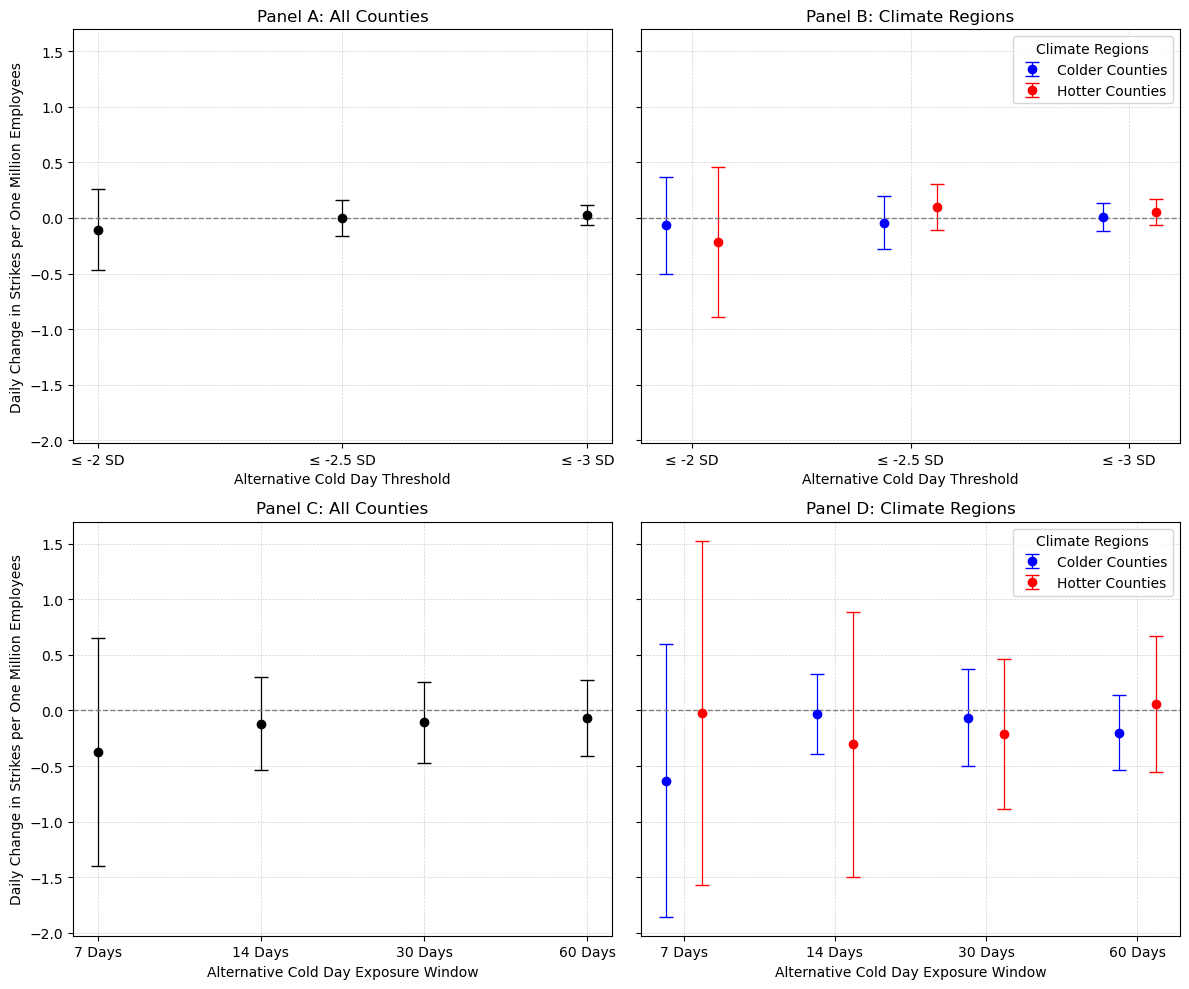

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =======================
# 1. CHANGING THRESHOLD
# =======================

thresholds_thresh = {
    "≤ -2 SD":   {"Winter": strikes_c1,   "Colder Counties": strikes_c1_CDD1,   "Hotter Counties": strikes_c1_CDD2,   "var": "cold_day_1"},
    "≤ -2.5 SD": {"Winter": strikes_c2,   "Colder Counties": strikes_c2_CDD1,   "Hotter Counties": strikes_c2_CDD2,   "var": "cold_day_2"},
    "≤ -3 SD":   {"Winter": strikes_c3,   "Colder Counties": strikes_c3_CDD1,   "Hotter Counties": strikes_c3_CDD2,   "var": "cold_day_3"},
}

outcome_labels_thresh = {
    "Winter":          "Winter",
    "Colder Counties": "Colder Counties",
    "Hotter Counties": "Hotter Counties",
}

rows_thresh = []

for thresh_label, info in thresholds_thresh.items():
    varname = info["var"]

    for outcome_key in ["Winter", "Colder Counties", "Hotter Counties"]:
        df = info[outcome_key]
        sub = df[df["Variable"] == varname]

        if sub.empty:
            print(f"⚠ Warning: {varname} not found in {outcome_key} at {thresh_label}")
            continue

        row = sub.iloc[0]
        est = row["est"]
        se  = row["se"]

        ci_low  = est - 1.96 * se
        ci_high = est + 1.96 * se

        rows_thresh.append([
            thresh_label,
            outcome_labels_thresh[outcome_key],
            est,
            ci_low,
            ci_high
        ])

plot_df_thresh = pd.DataFrame(
    rows_thresh,
    columns=["threshold", "outcome", "est", "ci_low", "ci_high"]
)

threshold_list_thresh = list(plot_df_thresh["threshold"].unique())
x_thresh = np.arange(len(threshold_list_thresh))

colors_thresh = {
    "Winter": "black",
    "Colder Counties": "blue",
    "Hotter Counties": "red",
}

# =======================
# 2. CHANGING WINDOW
# =======================

thresholds_window = {
    "7 Days":   {"Winter Days": strikes_w7,   "Colder Counties": strikes_w7_CDD1,   "Hotter Counties": strikes_w7_CDD2,   "var": "cold_day_7"},
    "14 Days":  {"Winter Days": strikes_w14,  "Colder Counties": strikes_w14_CDD1,  "Hotter Counties": strikes_w14_CDD2,  "var": "cold_day_14"},
    "30 Days":  {"Winter Days": strikes_w30,  "Colder Counties": strikes_w30_CDD1,  "Hotter Counties": strikes_w30_CDD2,  "var": "cold_day_30"},
    "60 Days":  {"Winter Days": strikes_w60,  "Colder Counties": strikes_w60_CDD1,  "Hotter Counties": strikes_w60_CDD2,  "var": "cold_day_60"},
}

outcome_labels_window = {
    "Winter Days":     "Winter Days",
    "Colder Counties": "Colder Counties",
    "Hotter Counties": "Hotter Counties",
}

rows_window = []

for thresh_label, info in thresholds_window.items():
    varname = info["var"]

    for outcome_key in ["Winter Days", "Colder Counties", "Hotter Counties"]:
        df = info[outcome_key]
        sub = df[df["Variable"] == varname]

        if sub.empty:
            print(f"⚠ Warning: {varname} not found in {outcome_key} at {thresh_label}")
            continue

        row = sub.iloc[0]
        est = row["est"]
        se  = row["se"]

        ci_low  = est - 1.96 * se
        ci_high = est + 1.96 * se

        rows_window.append([
            thresh_label,
            outcome_labels_window[outcome_key],
            est,
            ci_low,
            ci_high
        ])

plot_df_window = pd.DataFrame(
    rows_window,
    columns=["threshold", "outcome", "est", "ci_low", "ci_high"]
)

threshold_list_window = list(plot_df_window["threshold"].unique())
x_window = np.arange(len(threshold_list_window))

colors_window = {
    "Winter Days": "black",
    "Colder Counties": "blue",
    "Hotter Counties": "red",
}

# =======================
# 3. FOUR-PANEL FIGURE
# =======================

fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharey=True)

# ---------- Panel A: Changing Threshold – All Counties ----------
axA = axes[0, 0]
df_all_thresh = (
    plot_df_thresh[plot_df_thresh["outcome"] == "Winter"]
    .set_index("threshold")
    .loc[threshold_list_thresh]
)

axA.errorbar(
    x_thresh,
    df_all_thresh["est"],
    yerr=[
        df_all_thresh["est"] - df_all_thresh["ci_low"],
        df_all_thresh["ci_high"] - df_all_thresh["est"],
    ],
    fmt="o",
    capsize=5,
    linewidth=0.9,
    color=colors_thresh["Winter"],
    ecolor=colors_thresh["Winter"],
    mec=colors_thresh["Winter"],
    mfc=colors_thresh["Winter"],
    label="Winter",
)

axA.axhline(0, color="grey", linestyle="--", linewidth=1)
axA.grid(True, linestyle="--", linewidth=0.5, color="lightgrey")

axA.set_xticks(x_thresh)
axA.set_xticklabels(threshold_list_thresh)
axA.set_xlabel("Alternative Cold Day Threshold")
axA.set_ylabel("Daily Change in Strikes per One Million Employees")
axA.set_title("Panel A: All Counties")

# ---------- Panel B: Changing Threshold – Climate Regions ----------
axB = axes[0, 1]
offset = 0.12

for i, outcome in enumerate(["Colder Counties", "Hotter Counties"]):
    df_sub = (
        plot_df_thresh[plot_df_thresh["outcome"] == outcome]
        .set_index("threshold")
        .loc[threshold_list_thresh]
    )

    colour = colors_thresh[outcome]
    x_pos = x_thresh + (i - 0.5) * (2 * offset)

    axB.errorbar(
        x_pos,
        df_sub["est"],
        yerr=[
            df_sub["est"] - df_sub["ci_low"],
            df_sub["ci_high"] - df_sub["est"],
        ],
        fmt="o",
        capsize=5,
        linewidth=0.9,
        color=colour,
        ecolor=colour,
        mec=colour,
        mfc=colour,
        label=outcome,
    )

axB.axhline(0, color="grey", linestyle="--", linewidth=1)
axB.grid(True, linestyle="--", linewidth=0.5, color="lightgrey")

axB.set_xticks(x_thresh)
axB.set_xticklabels(threshold_list_thresh)
axB.set_xlabel("Alternative Cold Day Threshold")
axB.set_title("Panel B: Climate Regions")
axB.legend(title="Climate Regions")

# ---------- Panel C: Changing Window – All Counties ----------
axC = axes[1, 0]
df_all_window = (
    plot_df_window[plot_df_window["outcome"] == "Winter Days"]
    .set_index("threshold")
    .loc[threshold_list_window]
)

axC.errorbar(
    x_window,
    df_all_window["est"],
    yerr=[
        df_all_window["est"] - df_all_window["ci_low"],
        df_all_window["ci_high"] - df_all_window["est"],
    ],
    fmt="o",
    capsize=5,
    linewidth=0.9,
    color=colors_window["Winter Days"],
    ecolor=colors_window["Winter Days"],
    mec=colors_window["Winter Days"],
    mfc=colors_window["Winter Days"],
    label="Winter Days",
)

axC.axhline(0, color="grey", linestyle="--", linewidth=1)
axC.grid(True, linestyle="--", linewidth=0.5, color="lightgrey")

axC.set_xticks(x_window)
axC.set_xticklabels(threshold_list_window)
axC.set_xlabel("Alternative Cold Day Exposure Window")
axC.set_ylabel("Daily Change in Strikes per One Million Employees")
axC.set_title("Panel C: All Counties")

# ---------- Panel D: Changing Window – Climate Regions ----------
axD = axes[1, 1]

for i, outcome in enumerate(["Colder Counties", "Hotter Counties"]):
    df_sub = (
        plot_df_window[plot_df_window["outcome"] == outcome]
        .set_index("threshold")
        .loc[threshold_list_window]
    )

    colour = colors_window[outcome]
    x_pos = x_window + (i - 0.5) * (2 * offset)

    axD.errorbar(
        x_pos,
        df_sub["est"],
        yerr=[
            df_sub["est"] - df_sub["ci_low"],
            df_sub["ci_high"] - df_sub["est"],
        ],
        fmt="o",
        capsize=5,
        linewidth=0.9,
        color=colour,
        ecolor=colour,
        mec=colour,
        mfc=colour,
        label=outcome,
    )

axD.axhline(0, color="grey", linestyle="--", linewidth=1)
axD.grid(True, linestyle="--", linewidth=0.5, color="lightgrey")

axD.set_xticks(x_window)
axD.set_xticklabels(threshold_list_window)
axD.set_xlabel("Alternative Cold Day Exposure Window")
axD.set_title("Panel D: Climate Regions")
axD.legend(title="Climate Regions")

plt.tight_layout()
plt.show()


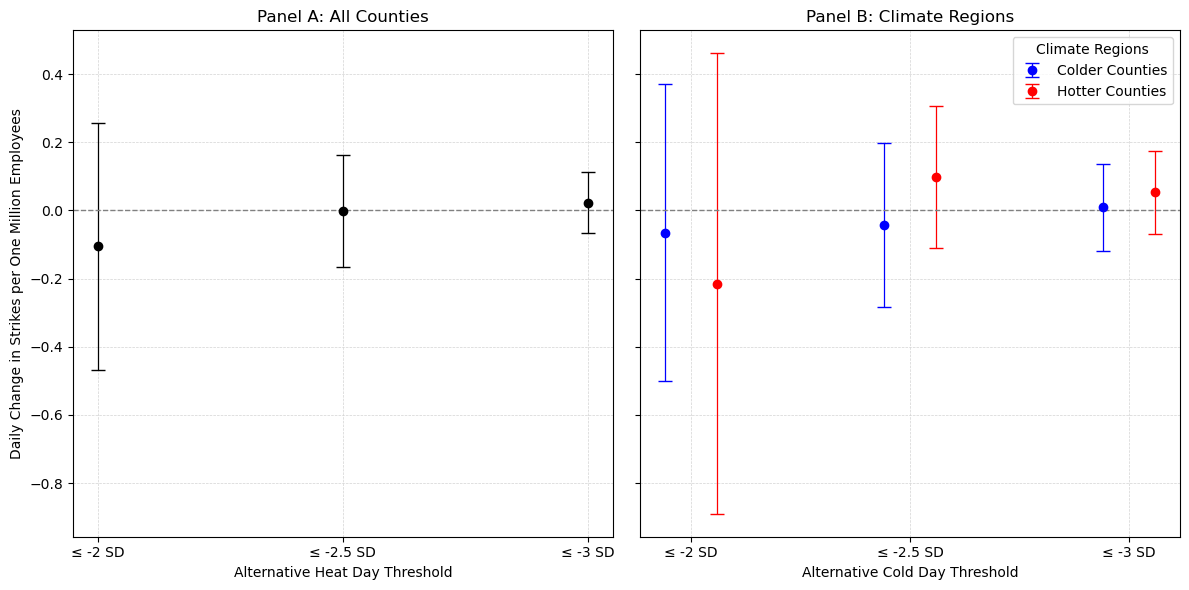

In [7]:
# Effect by Changing Threshold (Winter Strikes)- by Winter Days, Hot Region, Cold Region #
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Define thresholds and variable names
thresholds = {
    "≤ -2 SD":   {"Winter": strikes_c1,   "Colder Counties": strikes_c1_CDD1,   "Hotter Counties": strikes_c1_CDD2,   "var": "cold_day_1"},
    "≤ -2.5 SD": {"Winter": strikes_c2,   "Colder Counties": strikes_c2_CDD1,   "Hotter Counties": strikes_c2_CDD2,   "var": "cold_day_2"},
    "≤ -3 SD":   {"Winter": strikes_c3,   "Colder Counties": strikes_c3_CDD1,   "Hotter Counties": strikes_c3_CDD2,   "var": "cold_day_3"},
}

# Outcome labels
outcome_labels = {
    "Winter":   "Winter",
    "Colder Counties": "Colder Counties",
    "Hotter Counties":  "Hotter Counties",
}

# Extract rows for plotting
rows = []

for thresh_label, info in thresholds.items():
    varname = info["var"]

    for outcome_key in ["Winter", "Colder Counties", "Hotter Counties"]:
        df = info[outcome_key]
        sub = df[df["Variable"] == varname]

        if sub.empty:
            print(f"⚠ Warning: {varname} not found in {outcome_key} at {thresh_label}")
            continue

        row = sub.iloc[0]
        est = row["est"]
        se  = row["se"]

        ci_low  = est - 1.96 * se
        ci_high = est + 1.96 * se

        rows.append([
            thresh_label,
            outcome_labels[outcome_key],
            est,
            ci_low,
            ci_high
        ])

plot_df = pd.DataFrame(rows, columns=["threshold", "outcome", "est", "ci_low", "ci_high"])

# -------------------- PLOTTING --------------------

threshold_list = list(plot_df["threshold"].unique())
# Fix the order explicitly if needed:
# threshold_list = ["≥ 2 SD", "≥ 2.5 SD", "≥ 3 SD"]
x = np.arange(len(threshold_list))

outcome_colors = {
    "Winter": "black",
    "Colder Counties": "blue",
    "Hotter Counties": "red",
}

fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)

# ---------- Panel A: All Summer Days ----------
axA = axes[0]
df_all = (
    plot_df[plot_df["outcome"] == "Winter"]
    .set_index("threshold")
    .loc[threshold_list]
)

axA.errorbar(
    x,
    df_all["est"],
    yerr=[
        df_all["est"] - df_all["ci_low"],
        df_all["ci_high"] - df_all["est"],
    ],
    fmt="o",
    capsize=5,
    linewidth=0.9,
    color=outcome_colors["Winter"],
    ecolor=outcome_colors["Winter"],
    mec=outcome_colors["Winter"],
    mfc=outcome_colors["Winter"],
    label="Winter",
)

axA.axhline(0, color="grey", linestyle="--", linewidth=1)
axA.grid(True, linestyle="--", linewidth=0.5, color="lightgrey")

axA.set_xticks(x)
axA.set_xticklabels(threshold_list)
axA.set_xlabel("Alternative Heat Day Threshold")
axA.set_ylabel("Daily Change in Strikes per One Million Employees")
axA.set_title("Panel A: All Counties")
#axA.legend()

# ---------- Panel B: By Climate Region ----------
axB = axes[1]

offset = 0.12   # controls spacing between the two groups

for i, outcome in enumerate(["Colder Counties", "Hotter Counties"]):
    df_sub = (
        plot_df[plot_df["outcome"] == outcome]
        .set_index("threshold")
        .loc[threshold_list]
    )

    colour = outcome_colors[outcome]

    # Apply offset: colder = -offset, hotter = +offset
    x_pos = x + (i - 0.5) * (2 * offset)

    axB.errorbar(
        x_pos,
        df_sub["est"],
        yerr=[
            df_sub["est"] - df_sub["ci_low"],
            df_sub["ci_high"] - df_sub["est"],
        ],
        fmt="o",
        capsize=5,
        linewidth=0.9,
        color=colour,
        ecolor=colour,
        mec=colour,
        mfc=colour,
        label=outcome,
    )

axB.axhline(0, color="grey", linestyle="--", linewidth=1)
axB.grid(True, linestyle="--", linewidth=0.5, color="lightgrey")

axB.set_xticks(x)
axB.set_xticklabels(threshold_list)
axB.set_xlabel("Alternative Cold Day Threshold")
axB.set_title("Panel B: Climate Regions")
axB.legend(title="Climate Regions")

plt.tight_layout()
plt.show()

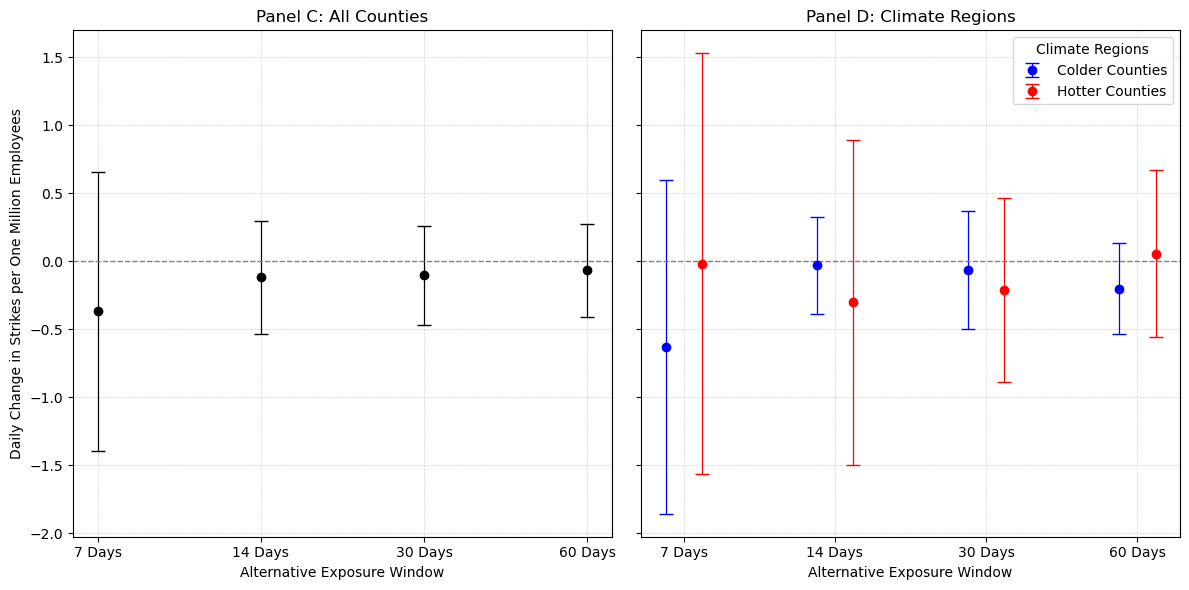

In [9]:
# Effect by Changing Window (Summer Strikes)- by All Summer Days, Hot Region, Cold Region #
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Define thresholds and variable names
thresholds = {
    "7 Days":   {"Winter Days": strikes_w7,   "Colder Counties": strikes_w7_CDD1,   "Hotter Counties": strikes_w7_CDD2,   "var": "cold_day_7"},
    "14 Days": {"Winter Days": strikes_w14,   "Colder Counties": strikes_w14_CDD1,   "Hotter Counties": strikes_w14_CDD2,   "var": "cold_day_14"},
    "30 Days":   {"Winter Days": strikes_w30,   "Colder Counties": strikes_w30_CDD1,   "Hotter Counties": strikes_w30_CDD2,   "var": "cold_day_30"},
    "60 Days":   {"Winter Days": strikes_w60,   "Colder Counties": strikes_w60_CDD1,   "Hotter Counties": strikes_w60_CDD2,   "var": "cold_day_60"},
}

# Outcome labels
outcome_labels = {
    "Winter Days":   "Winter Days",
    "Colder Counties": "Colder Counties",
    "Hotter Counties":  "Hotter Counties",
}

# Extract rows for plotting
rows = []

for thresh_label, info in thresholds.items():
    varname = info["var"]

    for outcome_key in ["Winter Days", "Colder Counties", "Hotter Counties"]:
        df = info[outcome_key]
        sub = df[df["Variable"] == varname]

        if sub.empty:
            print(f"⚠ Warning: {varname} not found in {outcome_key} at {thresh_label}")
            continue

        row = sub.iloc[0]
        est = row["est"]
        se  = row["se"]

        ci_low  = est - 1.96 * se
        ci_high = est + 1.96 * se

        rows.append([
            thresh_label,
            outcome_labels[outcome_key],
            est,
            ci_low,
            ci_high
        ])

plot_df = pd.DataFrame(rows, columns=["threshold", "outcome", "est", "ci_low", "ci_high"])

# -------------------- PLOTTING --------------------

threshold_list = list(plot_df["threshold"].unique())
# Fix the order explicitly if needed:
# threshold_list = ["≥ 2 SD", "≥ 2.5 SD", "≥ 3 SD"]
x = np.arange(len(threshold_list))

outcome_colors = {
    "Winter Days": "black",
    "Colder Counties": "blue",
    "Hotter Counties": "red",
}

fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)

# ---------- Panel A: All Summer Days ----------
axA = axes[0]
df_all = (
    plot_df[plot_df["outcome"] == "Winter Days"]
    .set_index("threshold")
    .loc[threshold_list]
)

axA.errorbar(
    x,
    df_all["est"],
    yerr=[
        df_all["est"] - df_all["ci_low"],
        df_all["ci_high"] - df_all["est"],
    ],
    fmt="o",
    capsize=5,
    linewidth=0.9,
    color=outcome_colors["Winter Days"],
    ecolor=outcome_colors["Winter Days"],
    mec=outcome_colors["Winter Days"],
    mfc=outcome_colors["Winter Days"],
    label="Winter Days",
)

axA.axhline(0, color="grey", linestyle="--", linewidth=1)
axA.grid(True, linestyle="--", linewidth=0.5, color="lightgrey")

axA.set_xticks(x)
axA.set_xticklabels(threshold_list)
axA.set_xlabel("Alternative Exposure Window")
axA.set_ylabel("Daily Change in Strikes per One Million Employees")
axA.set_title("Panel C: All Counties")
#axA.legend()

# ---------- Panel B: By Climate Region ----------
axB = axes[1]

offset = 0.12   # controls spacing between the two groups

for i, outcome in enumerate(["Colder Counties", "Hotter Counties"]):
    df_sub = (
        plot_df[plot_df["outcome"] == outcome]
        .set_index("threshold")
        .loc[threshold_list]
    )

    colour = outcome_colors[outcome]

    # Apply offset: colder = -offset, hotter = +offset
    x_pos = x + (i - 0.5) * (2 * offset)

    axB.errorbar(
        x_pos,
        df_sub["est"],
        yerr=[
            df_sub["est"] - df_sub["ci_low"],
            df_sub["ci_high"] - df_sub["est"],
        ],
        fmt="o",
        capsize=5,
        linewidth=0.9,
        color=colour,
        ecolor=colour,
        mec=colour,
        mfc=colour,
        label=outcome,
    )

axB.axhline(0, color="grey", linestyle="--", linewidth=1)
axB.grid(True, linestyle="--", linewidth=0.5, color="lightgrey")

axB.set_xticks(x)
axB.set_xticklabels(threshold_list)
axB.set_xlabel("Alternative Exposure Window")
axB.set_title("Panel D: Climate Regions")
axB.legend(title="Climate Regions")

plt.tight_layout()
plt.show()
